# Cómo aprende el modelo de acordes, paso a paso

Este cuaderno recorre el proyecto de punta a punta con una partitura real: **«Believer»**, del
conjunto *dev*. Cada celda hace una sola cosa y muestra su resultado. Ejecútalas en orden con
`Shift + Enter`.

**Cómo abrirlo:** desde la raíz del proyecto, `uv run jupyter lab` y abre `notebooks/paso_a_paso.ipynb`.

**Una regla del proyecto:** aquí solo se miran partituras de *dev*. Las de *test* son el examen
final y no se miran para no "aprender" de ellas sin querer.

| Paso | Qué verás |
|---|---|
| 1 | La partitura: notas y acordes escritos |
| 2 | El grafo: nodos, aristas y los 30 rasgos de una nota |
| 3 | Las etiquetas: qué acorde le toca a cada nota |
| 4 | El modelo sin entrenar: adivina al azar |
| 5 | Entrenar en directo: la pérdida baja |
| 6 | El modelo bueno: compás a compás, escrito frente a predicho |
| 7 | Sus errores típicos |

In [1]:
import os, warnings
from pathlib import Path

warnings.filterwarnings("ignore")
if Path.cwd().name == "notebooks":  # el cuaderno vive en notebooks/: trabajamos desde la raíz
    os.chdir("..")

import numpy as np
import torch
import matplotlib.pyplot as plt

from acordes_gnn.datos import cargar_splits, ruta_de

torch.set_num_threads(4)  # con grafos pequeños, más hilos van MÁS lentos
splits = cargar_splits()
NOMBRE = "QmQxXjUwHjhW3TfQGcaZGqrdPW49AsaCw7VPZB2EXTj2DA.musicxml"  # «Believer»
RUTA = ruta_de(NOMBRE)
print(RUTA.name, "· ¿está en dev?", NOMBRE in splits["dev"], "· ¿en test?", NOMBRE in splits["test"])

QmQxXjUwHjhW3TfQGcaZGqrdPW49AsaCw7VPZB2EXTj2DA.musicxml · ¿está en dev? True · ¿en test? False


## Paso 1 · La partitura

Una red neuronal no lee partituras: necesita números. Lo primero es sacar del MusicXML **las notas**
(con partitura) y **los acordes que escribió el arreglista** (con music21). Esos acordes son la
"respuesta correcta" de la que aprende el modelo.

In [2]:
from acordes_gnn.grafo import leer_notas
from acordes_gnn.etiquetas import nombre_nota

notas = leer_notas(RUTA)
na = notas.array
print(f"{len(na)} notas en {len(notas.inicios_compas)} compases\n")
for i in range(12):
    f = na[i]
    mano = "izq." if f["staff"] >= 2 else "der."
    print(f"compás {notas.compas[i] + 1:2d} · negra {f['onset_quarter']:6.2f} · {nombre_nota(f):5} · "
          f"dura {f['duration_quarter']:.2f} negras · mano {mano}")

650 notas en 59 compases

compás  1 · negra   0.00 · La2   · dura 4.00 negras · mano izq.
compás  1 · negra   0.00 · La3   · dura 4.00 negras · mano izq.
compás  1 · negra   0.00 · La4   · dura 1.00 negras · mano der.
compás  1 · negra   1.00 · Mi5   · dura 1.00 negras · mano der.
compás  1 · negra   2.00 · Re5   · dura 1.00 negras · mano der.
compás  1 · negra   3.00 · Re5   · dura 0.50 negras · mano der.
compás  1 · negra   3.50 · Do5   · dura 0.50 negras · mano der.
compás  2 · negra   4.00 · La2   · dura 4.00 negras · mano izq.
compás  2 · negra   4.00 · La3   · dura 4.00 negras · mano izq.
compás  2 · negra   4.00 · Re5   · dura 1.00 negras · mano der.
compás  2 · negra   5.00 · Re5   · dura 0.50 negras · mano der.
compás  2 · negra   5.50 · Mi5   · dura 0.50 negras · mano der.


In [3]:
from acordes_gnn.etiquetas import leer_referencia, ubicar

acordes, silencios, _ = leer_referencia(RUTA)
ubicar(acordes, notas.inicios_compas)  # cada acorde, en el mismo eje de tiempo que las notas
print(f"{len(acordes)} acordes escritos\n")
for a in acordes[:12]:
    print(f"compás {a.indice + 1:2d}, tiempo {a.offset + 1:g}: {a.figura:7} → raíz {a.raiz:2d} (0 = Do), calidad «{a.calidad}»")

56 acordes escritos

compás  1, tiempo 2: Am      → raíz  9 (0 = Do), calidad «menor»
compás  2, tiempo 3: Am      → raíz  9 (0 = Do), calidad «menor»
compás  3, tiempo 3: F       → raíz  5 (0 = Do), calidad «mayor»
compás  4, tiempo 2.5: E       → raíz  4 (0 = Do), calidad «mayor»
compás  5, tiempo 2: Am      → raíz  9 (0 = Do), calidad «menor»
compás  6, tiempo 3: Am      → raíz  9 (0 = Do), calidad «menor»
compás  7, tiempo 2: F       → raíz  5 (0 = Do), calidad «mayor»
compás  8, tiempo 1: E       → raíz  4 (0 = Do), calidad «mayor»
compás  9, tiempo 2: Am      → raíz  9 (0 = Do), calidad «menor»
compás 10, tiempo 3: Am      → raíz  9 (0 = Do), calidad «menor»
compás 11, tiempo 3: F       → raíz  5 (0 = Do), calidad «sus»
compás 12, tiempo 2.5: E       → raíz  4 (0 = Do), calidad «mayor»


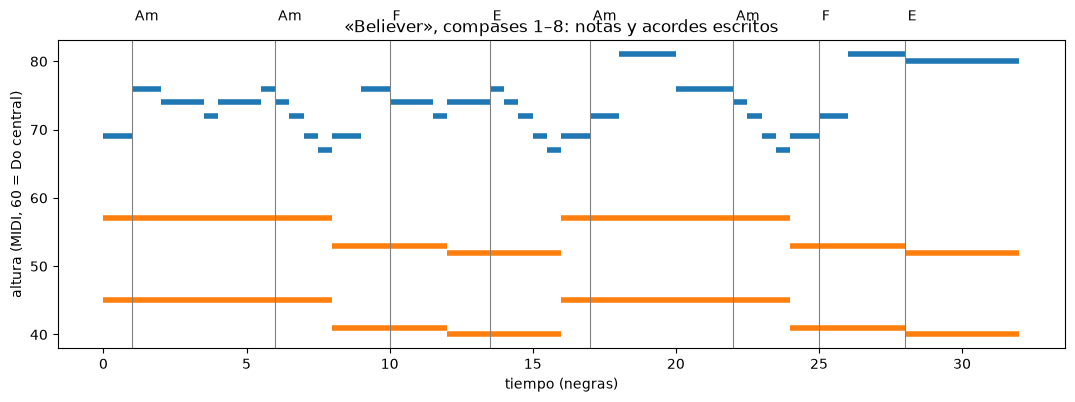

In [4]:
# Dibujo de los primeros 8 compases: cada nota es una raya (azul = mano derecha, naranja = izquierda)
# y las líneas grises verticales marcan dónde está escrito cada acorde.
hasta = notas.inicios_compas[min(8, len(notas.inicios_compas) - 1)]
fig, ax = plt.subplots(figsize=(13, 4))
for f in na[na["onset_quarter"] < hasta]:
    ax.plot([f["onset_quarter"], f["onset_quarter"] + f["duration_quarter"]], [f["pitch"]] * 2,
            lw=4, color="tab:orange" if f["staff"] >= 2 else "tab:blue", solid_capstyle="butt")
for a in acordes:
    if a.tiempo < hasta:
        ax.axvline(a.tiempo, color="gray", lw=0.8)
        ax.text(a.tiempo + 0.1, na["pitch"].max() + 2, a.figura, fontsize=10)
ax.set_xlabel("tiempo (negras)"); ax.set_ylabel("altura (MIDI, 60 = Do central)")
ax.set_title("«Believer», compases 1–8: notas y acordes escritos")
plt.show()

## Paso 2 · El grafo

GraphMuse convierte las notas en un **grafo**: cada nota es un **nodo** y las **aristas** dicen cómo
se relacionan en el tiempo (empiezan a la vez, una sigue a la otra, una suena mientras empieza la
otra…). Además hay nodos virtuales para cada **compás** y cada **pulso**.

In [5]:
from acordes_gnn.grafo import construir_grafo, NOMBRES_RASGOS

grafo = construir_grafo(notas)
for t in grafo.node_types:
    print(f"nodos   {t:8} {grafo[t].num_nodes:6d}")
print()
for (a, rel, b) in grafo.edge_types:
    print(f"aristas {a:7} —{rel:16}→ {b:7} {grafo[a, rel, b].edge_index.shape[1]:6d}")

nodos   note        650
nodos   measure      59
nodos   beat        233

aristas note    —onset           → note      1482
aristas note    —consecutive     → note      1444
aristas note    —during          → note       278
aristas note    —rest            → note         0
aristas note    —consecutive_rev → note      1444
aristas note    —during_rev      → note       278
aristas note    —rest_rev        → note         0
aristas note    —connects        → measure    650
aristas measure —connects        → note       650
aristas measure —next            → measure     58
aristas note    —connects        → beat       650
aristas beat    —connects        → note       650
aristas beat    —next            → beat       232


In [6]:
# Los 30 números que describen una nota ANTES de que el modelo mire a sus vecinas
i = 40
print("nota", i, "·", nombre_nota(na[i]), "· compás", notas.compas[i] + 1)
for nombre_rasgo, v in zip(NOMBRES_RASGOS, grafo["note"].x[i].tolist()):
    if v:
        print(f"   {nombre_rasgo:16} {v:.2f}")

nota 40 · Mi5 · compás 6
   pc_E             1.00
   altura           0.67
   duracion         0.88
   posicion_compas  0.38
   grado_3          1.00


In [7]:
# Sus vecinas en el grafo: de quién recibirá "mensajes" en cada capa
for rel in ("onset", "consecutive", "during"):
    ei = grafo["note", rel, "note"].edge_index
    vecinas = ei[1, ei[0] == i].tolist()
    print(f"[{rel:11}] {[nombre_nota(na[j]) for j in vecinas]}")

[onset      ] ['Mi5']
[consecutive] ['Re5']
[during     ] []


## Paso 3 · Las etiquetas

Aprendizaje **supervisado**: cada nota recibe como respuesta correcta el acorde escrito que está
vigente cuando empieza a sonar. Hay 60 respuestas posibles (12 raíces × 5 calidades). Las notas sin
acorde vigente quedan **sin etiqueta** (−100) y no cuentan al entrenar.

In [8]:
from acordes_gnn.etiquetas import etiquetar_notas, nombre, SIN_ETIQUETA

inicios = notas.inicios_compas
sil_t = [float(inicios[min(c, len(inicios) - 1)]) + o for c, o in silencios]
y = etiquetar_notas(na["onset_quarter"], acordes, sil_t)
print(f"notas sin etiqueta: {(y == SIN_ETIQUETA).mean():.1%}\n")
for k in range(15):
    print(f"{nombre_nota(na[k]):5} (compás {notas.compas[k] + 1}) → {nombre(int(y[k])) if y[k] >= 0 else '(sin etiqueta)'}")

notas sin etiqueta: 0.5%

La2   (compás 1) → (sin etiqueta)
La3   (compás 1) → (sin etiqueta)
La4   (compás 1) → (sin etiqueta)
Mi5   (compás 1) → Am
Re5   (compás 1) → Am
Re5   (compás 1) → Am
Do5   (compás 1) → Am
La2   (compás 2) → Am
La3   (compás 2) → Am
Re5   (compás 2) → Am
Re5   (compás 2) → Am
Mi5   (compás 2) → Am
Re5   (compás 2) → Am
Do5   (compás 2) → Am
La4   (compás 2) → Am


## Paso 4 · El modelo, antes de aprender

El modelo empieza con pesos **al azar**. Por cada nota devuelve 60 números (*logits*), uno por
acorde. La **pérdida** (entropía cruzada) mide cuánto se equivoca: si adivina al azar entre 60,
vale ln 60 ≈ 4.1.

In [9]:
from acordes_gnn.modelo import crear_modelo, contar_parametros

grafo = construir_grafo(notas, y)  # el mismo grafo, ahora con la respuesta de cada nota
torch.manual_seed(0)
modelo = crear_modelo("propio", grafo.metadata(), oculto=64)
print(f"{contar_parametros(modelo):,} parámetros (números que se ajustan al entrenar)")

332,988 parámetros (números que se ajustan al entrenar)


In [10]:
with torch.no_grad():
    logits = modelo(grafo.x_dict, grafo.edge_index_dict)
y_t = grafo["note"].y
con = y_t >= 0
perdida = torch.nn.functional.cross_entropy(logits, y_t, ignore_index=SIN_ETIQUETA)
print("salida:", tuple(logits.shape), "= (notas, 60 acordes)")
print(f"pérdida {perdida:.2f} · adivinar al azar = ln 60 = {np.log(60):.2f}")
print(f"acierto por nota sin entrenar: {(logits.argmax(-1)[con] == y_t[con]).float().mean():.1%} (al azar ≈ 1/60 = 1.7 %)")

salida: (650, 60) = (notas, 60 acordes)
pérdida 4.40 · adivinar al azar = ln 60 = 4.09
acierto por nota sin entrenar: 1.2% (al azar ≈ 1/60 = 1.7 %)


## Paso 5 · Entrenar en directo

Una versión mini del bucle de `entrenar.py`: 40 partituras de train, 8 épocas, en la CPU. En cada
lote: **forward** (predecir), **pérdida** (cuánto falla, pesada por acorde), **backward** (cuánto
influye cada peso) y **paso** (mover los pesos un poquito). Al final de cada época se mide en dev.

In [11]:
from torch_geometric.loader import DataLoader
from acordes_gnn.dataset import CorpusAcordes, nombres_de
from acordes_gnn.entrenar import pesos_por_acorde
from acordes_gnn.evaluar import evaluar_piezas

torch.manual_seed(0)
train = CorpusAcordes(nombres_de("train")[:40], aumentar=True, semilla=0)  # cada vez, transpuesta al azar
dev = CorpusAcordes(nombres_de("dev"))
cargador = DataLoader(train, batch_size=8, shuffle=True)
modelo = crear_modelo("propio", train.piezas[0]["grafo"].metadata(), oculto=64)
opt = torch.optim.AdamW(modelo.parameters(), lr=3e-3, weight_decay=1e-4)

historial = []
for epoca in range(1, 9):
    modelo.train()
    perdidas = []
    for lote in cargador:
        logits = modelo(lote.x_dict, lote.edge_index_dict)                       # 1. forward
        y_lote = lote["note"].y
        por_nota = torch.nn.functional.cross_entropy(logits, y_lote, ignore_index=SIN_ETIQUETA, reduction="none")
        w = pesos_por_acorde(y_lote, lote["note"].batch)                          # cada acorde cuenta igual
        perdida = (por_nota * w).sum() / w.sum()                                  # 2. pérdida
        opt.zero_grad()
        perdida.backward()                                                        # 3. backward
        opt.step()                                                                # 4. paso
        perdidas.append(perdida.item())
    res = evaluar_piezas(modelo, dev.piezas)
    historial.append((float(np.mean(perdidas)), res["calidad"]))
    print(f"época {epoca}: pérdida {historial[-1][0]:.3f} · dev raíz+calidad {res['calidad']:.1%}")

época 1: pérdida 3.977 · dev raíz+calidad 16.1%


época 2: pérdida 3.604 · dev raíz+calidad 4.2%


época 3: pérdida 3.497 · dev raíz+calidad 10.1%


época 4: pérdida 3.251 · dev raíz+calidad 25.8%


época 5: pérdida 3.167 · dev raíz+calidad 34.0%


época 6: pérdida 2.925 · dev raíz+calidad 44.9%


época 7: pérdida 2.801 · dev raíz+calidad 51.0%


época 8: pérdida 2.574 · dev raíz+calidad 54.8%


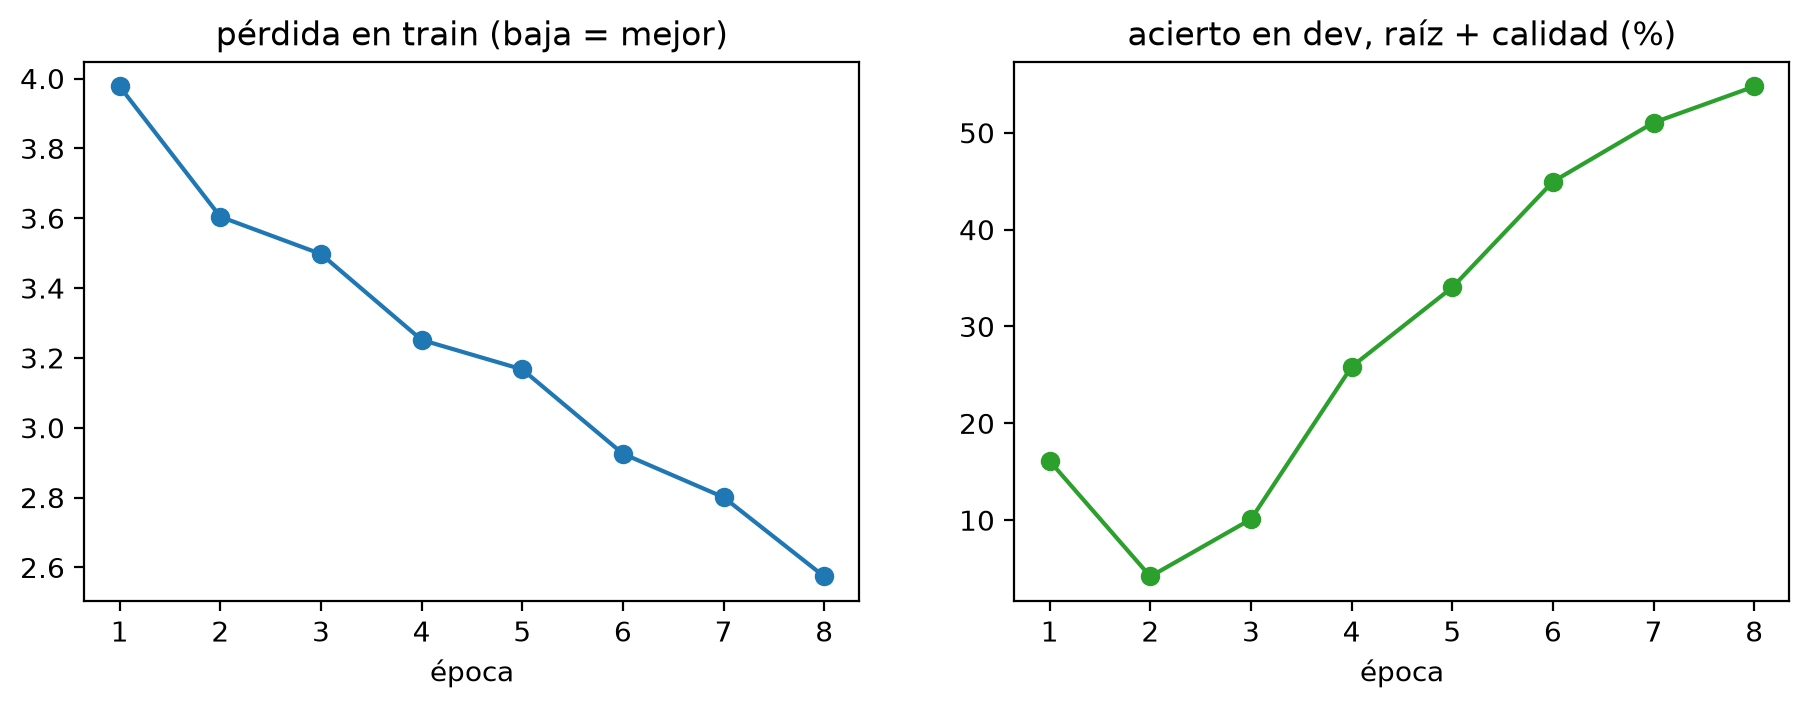

Con solo 40 partituras y 8 épocas ya aprende bastante. El modelo bueno usa ~1 200 partituras y la GPU.


In [12]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.5))
a1.plot(range(1, len(historial) + 1), [h[0] for h in historial], marker="o"); a1.set_title("pérdida en train (baja = mejor)")
a2.plot(range(1, len(historial) + 1), [h[1] * 100 for h in historial], marker="o", color="tab:green"); a2.set_title("acierto en dev, raíz + calidad (%)")
for a in (a1, a2): a.set_xlabel("época")
plt.show()
print("Con solo 40 partituras y 8 épocas ya aprende bastante. El modelo bueno usa ~1 200 partituras y la GPU.")

## Paso 6 · El modelo bueno

`modelos/mejor.pt` es el mejor modelo entrenado hasta ahora. Para cada acorde escrito de «Believer»,
el modelo junta las probabilidades de las notas que empiezan en ese instante y elige el acorde más
probable. Así se compara con lo escrito, compás a compás.

In [13]:
from acordes_gnn.dataset import cargar
from acordes_gnn.evaluar import cargar_modelo, comparar, predecir_en_puntos, notas_del_instante

mejor, ck = cargar_modelo("modelos/mejor.pt")
cfg = ck["config"]
print(f"modelo: oculto {cfg['oculto']}, {cfg['capas']} capas, {contar_parametros(mejor):,} parámetros, "
      f"datos «{cfg.get('datos', 'dos_manos')}», época {ck['epoca']}")

p = cargar(NOMBRE)
g = p["grafo"]
with torch.no_grad():
    prob = mejor(g.x_dict, g.edge_index_dict, onset=g["note"].onset_q).softmax(-1)
preds = predecir_en_puntos(prob, g["note"].onset_q, g["note"].dur_q, [a["tiempo"] for a in p["acordes"]])
aciertos = 0
for a, pr in zip(p["acordes"], preds):
    bien = comparar(pr, a)[1]
    aciertos += bien
    print(f"compás {a['indice'] + 1:3d}, tiempo {a['offset'] + 1:g}: escrito {a['figura']:7} · modelo {nombre(pr):5} {'✓' if bien else '✗'}")
print(f"\n«Believer»: {aciertos}/{len(preds)} = {aciertos / len(preds):.1%}")

modelo: oculto 256, 3 capas, 5,165,628 parámetros, datos «todo_pop909», época 10
compás   1, tiempo 2: escrito Am      · modelo Am    ✓
compás   2, tiempo 3: escrito Am      · modelo Am    ✓
compás   3, tiempo 3: escrito F       · modelo F     ✓
compás   4, tiempo 2.5: escrito E       · modelo Em    ✗
compás   5, tiempo 2: escrito Am      · modelo Am    ✓
compás   6, tiempo 3: escrito Am      · modelo Am    ✓
compás   7, tiempo 2: escrito F       · modelo F     ✓
compás   8, tiempo 1: escrito E       · modelo E     ✓
compás   9, tiempo 2: escrito Am      · modelo Am    ✓
compás  10, tiempo 3: escrito Am      · modelo Am    ✓
compás  11, tiempo 3: escrito F       · modelo F     ✗
compás  12, tiempo 2.5: escrito E       · modelo Em    ✗
compás  13, tiempo 2: escrito Am      · modelo Am    ✓
compás  14, tiempo 3: escrito Am      · modelo Am    ✓
compás  15, tiempo 2: escrito F       · modelo F     ✓
compás  16, tiempo 1: escrito E       · modelo E     ✓
compás  17, tiempo 1: escrito Am   

In [14]:
# Cuando falla, ¿estaba seguro o dudaba? Las 3 opciones más probables en cada fallo:
for a, pr in zip(p["acordes"], preds):
    if not comparar(pr, a)[1]:
        idx = notas_del_instante(g["note"].onset_q, g["note"].dur_q, a["tiempo"])
        media = prob[idx].mean(0)
        top = media.topk(3)
        opciones = ", ".join(f"{nombre(int(c))} {v:.0%}" for v, c in zip(top.values, top.indices))
        print(f"compás {a['indice'] + 1:3d}: escrito {a['figura']:7} → {opciones}")

compás   4: escrito E       → Em 74%, Esus 7%, E 6%
compás  11: escrito F       → F 85%, Dm 13%, Am 1%
compás  12: escrito E       → Em 42%, E 25%, Bdim 9%
compás  54: escrito F       → Am 83%, A 13%, D 1%


**Fíjate en el compás 11:** el modelo dice **F** (su opción más probable) y aun así cuenta como fallo. No es un
error del modelo: en el MusicXML, el arreglista escribió ese acorde con el tipo `other` y el texto
"e" (seguramente una errata). music21 lo lee como *solo la nota Fa*, sin tercera, así que la
"respuesta correcta" es «sin tercera» y F mayor no coincide. Es un ejemplo real de **etiqueta
ruidosa**: el modelo acierta musicalmente y el examen se lo cuenta como fallo. Afecta igual a
todos los métodos (el heurístico y Claude se midieron con la misma regla).

## Paso 7 · Sus errores típicos (en las 20 partituras de dev)

¿Con qué acordes se confunde? Casi siempre con acordes que **comparten dos notas** con el correcto
(Am ↔ F, Em ↔ C) o que están **a una quinta** (el anterior o el siguiente de la progresión).

mayor  acierto 92.7% (730 acordes)
menor  acierto 87.2% (344 acordes)
dim    acierto 44.4% (18 acordes)
sus    acierto  0.0% (7 acordes)


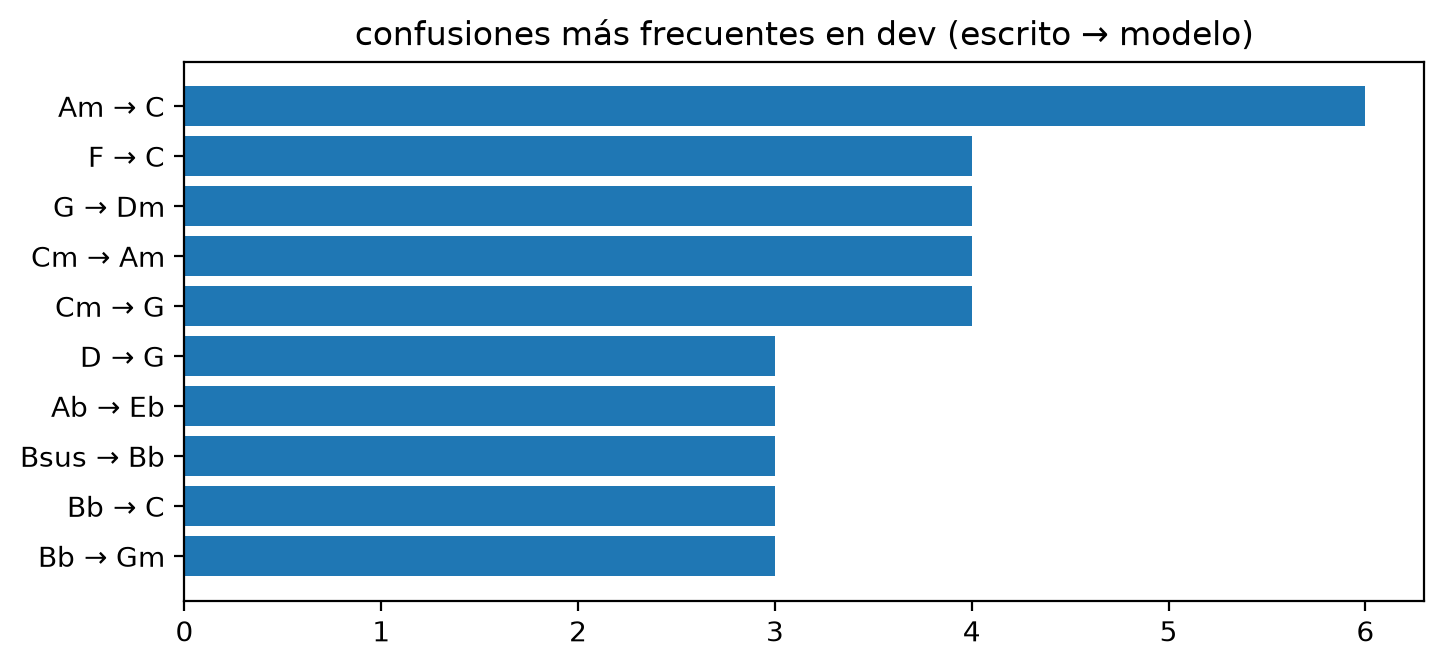

In [15]:
from collections import Counter
from acordes_gnn.etiquetas import CALIDAD_M21, RAICES

a_calidad = {v: k for k, v in CALIDAD_M21.items()}
sufijo = {"mayor": "", "menor": "m", "dim": "dim", "aum": "+", "sus": "sus"}
confusiones, por_tipo, bien_tipo = Counter(), Counter(), Counter()
for pieza in dev.piezas:
    g, A = pieza["grafo"], pieza["acordes"]
    with torch.no_grad():
        pr_ = mejor(g.x_dict, g.edge_index_dict, onset=g["note"].onset_q).softmax(-1)
    for a, c in zip(A, predecir_en_puntos(pr_, g["note"].onset_q, g["note"].dur_q, [x["tiempo"] for x in A])):
        tipo = a_calidad.get(a["calidad_m21"], "sus")
        por_tipo[tipo] += 1
        if comparar(c, a)[1]:
            bien_tipo[tipo] += 1
        else:
            confusiones[(RAICES[a["raiz"]] + sufijo[tipo], nombre(c))] += 1
for t, n in por_tipo.most_common():
    print(f"{t:6} acierto {bien_tipo[t] / n:5.1%} ({n} acordes)")
top = confusiones.most_common(10)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh([f"{e} → {m}" for (e, m), _ in top][::-1], [v for _, v in top][::-1])
ax.set_title("confusiones más frecuentes en dev (escrito → modelo)")
plt.show()

## Para seguir explorando

- Cambia `NOMBRE` por otra partitura de `splits["dev"]` y vuelve a ejecutar todo.
- En el paso 5, prueba `oculto=128` o más épocas: ¿sube el acierto en dev?
- En el paso 5, quita `pesos_por_acorde` (usa `por_nota.mean()`): ¿qué pasa con los acordes cortos?
- El documento de aprendizaje cuenta todos los experimentos; el README tiene la tabla de resultados.